# Imports

In [20]:
import os
import numpy as np
from torchvision.datasets import EMNIST
from sklearn.ensemble import RandomForestClassifier
import time
from sklearn.metrics import accuracy_score, classification_report

# Let's load in the data

In [11]:
DATA_DIR = os.path.expanduser("~/datasets/emnist")
os.makedirs(DATA_DIR, exist_ok=True)

# Downloads ~500MB once, cached after that
train = EMNIST(root=DATA_DIR, split="letters", train=True, download=True)
test = EMNIST(root=DATA_DIR, split="letters", train=False, download=True)

100%|██████████| 562M/562M [00:15<00:00, 36.6MB/s] 


In [21]:
N_TREES = 300
QUICK = False        
SEED = 42

def to_numpy(ds):
    X = ds.data.numpy().reshape(len(ds), -1)   # (N, 784) uint8, no scaling needed for trees
    y = ds.targets.numpy()                      # 1..26 = a..z
    return X, y

Xtr, ytr = to_numpy(train)   # 124,800 samples
Xte, yte = to_numpy(test)    # 20,800 samples

if QUICK:
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(Xtr), 20_000, replace=False)
    Xtr, ytr = Xtr[idx], ytr[idx]

print(f"Train: {Xtr.shape}, Test: {Xte.shape}")

# ---------- Train ----------
rf = RandomForestClassifier(
    n_estimators=N_TREES,
    n_jobs=-1,
    random_state=SEED,
)

t0 = time.time()
rf.fit(Xtr, ytr)
print(f"Training time: {time.time() - t0:.1f}s")

# ---------- Evaluate ----------
pred = rf.predict(Xte)
print(f"Test accuracy: {accuracy_score(yte, pred):.4f}")

letters = [chr(ord('a') + i) for i in range(26)]
print(classification_report(yte, pred, target_names=letters, digits=3))

Train: (124800, 784), Test: (20800, 784)
Training time: 122.1s
Test accuracy: 0.8900
              precision    recall  f1-score   support

           a      0.802     0.891     0.844       800
           b      0.917     0.926     0.922       800
           c      0.931     0.917     0.924       800
           d      0.901     0.885     0.893       800
           e      0.900     0.921     0.910       800
           f      0.926     0.906     0.916       800
           g      0.847     0.704     0.769       800
           h      0.908     0.874     0.890       800
           i      0.729     0.750     0.739       800
           j      0.896     0.895     0.896       800
           k      0.893     0.906     0.900       800
           l      0.730     0.735     0.733       800
           m      0.952     0.961     0.956       800
           n      0.885     0.892     0.889       800
           o      0.887     0.969     0.926       800
           p      0.927     0.954     0.940       

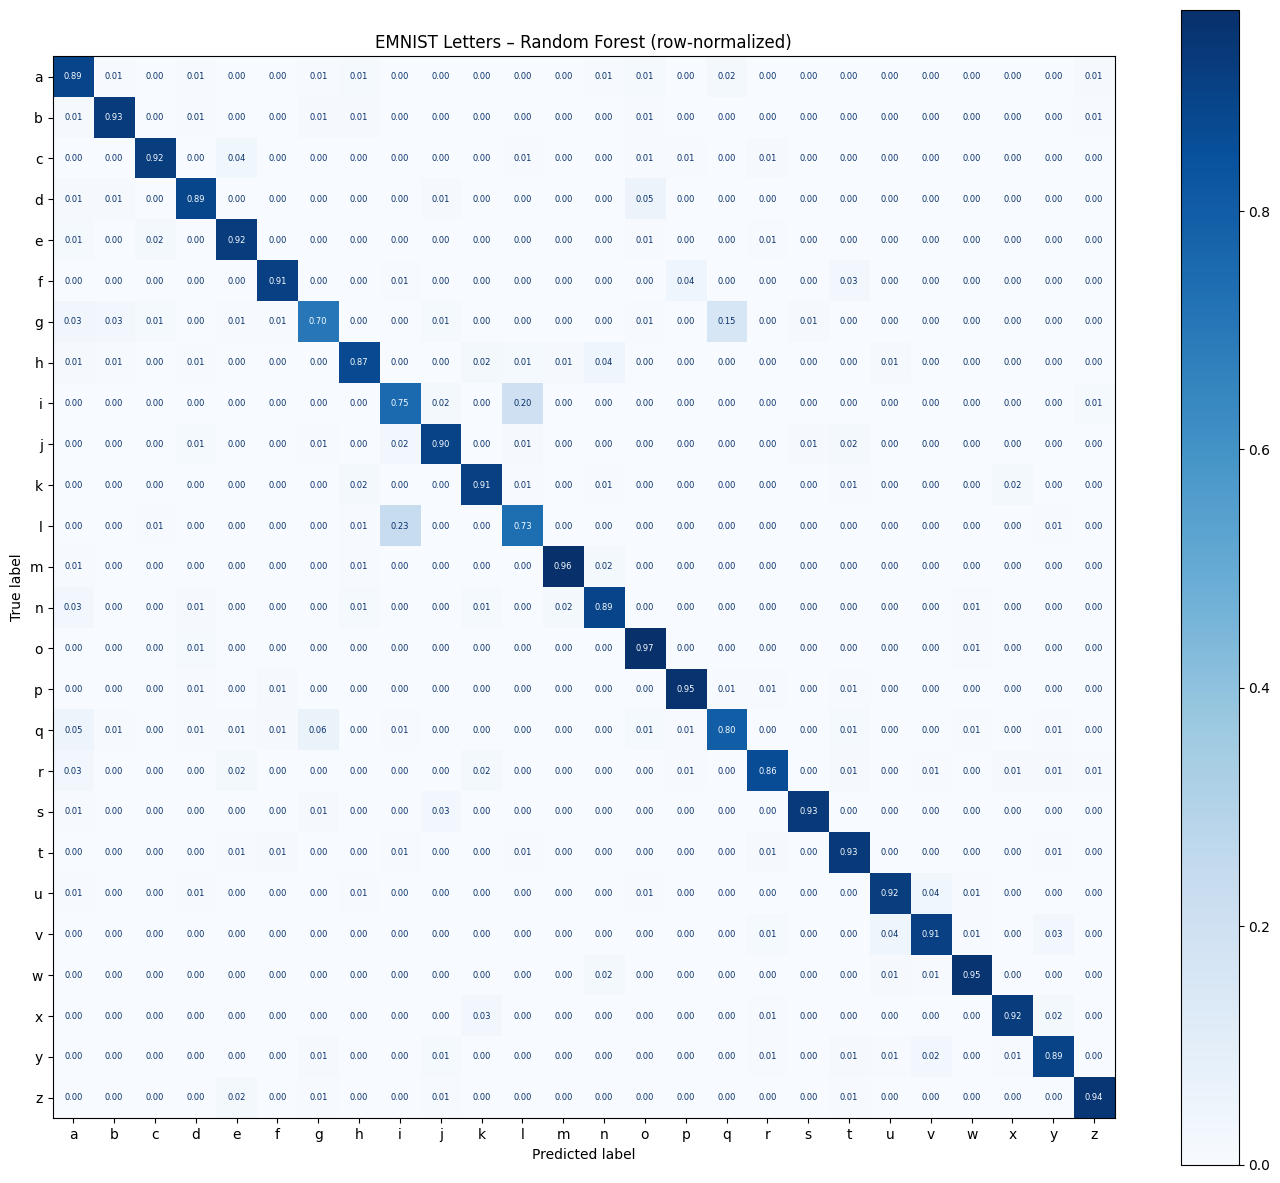

Most common confusions (true → predicted):
  l → i: 22.8%
  i → l: 20.2%
  g → q: 15.4%
  q → g: 6.1%
  d → o: 5.4%
  q → a: 4.6%
  h → n: 4.0%
  f → p: 3.9%
  v → u: 3.9%
  u → v: 3.5%
  c → e: 3.5%
  g → a: 3.4%
  n → a: 3.0%
  r → a: 2.9%
  x → k: 2.8%


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

letters = [chr(ord('a') + i) for i in range(26)]

# Row-normalized: each row = true letter, values = fraction predicted as each letter
cm = confusion_matrix(yte, pred, labels=range(1, 27), normalize="true")

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(cm, display_labels=letters)
disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=True)
ax.set_title("EMNIST Letters – Random Forest (row-normalized)")
plt.setp(ax.texts, fontsize=6)          # shrink the cell numbers
plt.tight_layout()
plt.show()

# ---------- Top confused pairs ----------
off = cm.copy()
np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1], off.shape))[0][:15]

print("Most common confusions (true → predicted):")
for i, j in top:
    print(f"  {letters[i]} → {letters[j]}: {off[i, j]:.1%}")